<a href="https://colab.research.google.com/github/Domiclement/NEXAFRICA-CUSTOMER_CHURN_ANALYSIS/blob/main/Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**CUSTOMER CHURN ANALYSIS**

WEEK 1: Business Understanding, Data Collection & Data Preparation

**Objective**

Understand the customer churn problem, explore the dataset, and prepare the data for analysis.

**Task 1: To Understand the Business Problem**

Customer churn refers to the phenomenon where customers discontinue their relationship or subscription with a company or service provider. It represents the rate at which customers stop using a company's products or services within a specific period. Churn is an important metric for businesses as it directly impacts revenue, growth, and customer retention.

Understanding customer churn is crucial for businesses to identify patterns, factors, and indicators that contribute to customer attrition. By analyzing churn behavior and its associated features, companies can develop strategies to retain existing customers, improve customer satisfaction, and reduce customer turnover. Predictive modeling techniques can also be applied to forecast and proactively address potential churn, enabling companies to take proactive measures to retain at-risk customers.



**Problem Statement**

The objective of this project is to develop a Machine Learning classification model that predicts
whether a customer is likely to churn based on demographic information, account details,
subscription information, service usage, contract type, tenure, and billing information.

Task 2: Obtain and Load the Dataset

In [9]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder



In [10]:
import kagglehub

path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Dataset path:", path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Dataset path: /kaggle/input/telco-customer-churn


In [11]:
print(os.listdir(path))

['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [12]:
file_path = os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(file_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [13]:
df.shape

(7043, 21)

In [14]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [15]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [17]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,3186-AJIEK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [18]:
data_dictionary = {
    "Feature": [
        "customerID",
        "gender",
        "SeniorCitizen",
        "Partner",
        "Dependents",
        "tenure",
        "Contract",
        "MonthlyCharges",
        "TotalCharges",
        "PaymentMethod",
        "Churn"
    ],

    "Description": [
        "Unique customer identifier",
        "Customer's gender",
        "Whether the customer is a senior citizen",
        "Whether the customer has a partner",
        "Whether the customer has dependents",
        "Number of months the customer has stayed with the company",
        "Customer's contract type",
        "Monthly amount charged to the customer",
        "Total amount charged to the customer",
        "Customer's payment method",
        "Whether the customer left the company"
    ],

    "Type": [
        "Categorical",
        "Categorical",
        "Categorical",
        "Categorical",
        "Categorical",
        "Numerical",
        "Categorical",
        "Numerical",
        "Numerical",
        "Categorical",
        "Target"
    ]
}

In [19]:
dictionary_df = pd.DataFrame(data_dictionary)

dictionary_df

,Feature,Description,Type
0,customerID,Unique customer identifier,Categorical
1,gender,Customer's gender,Categorical
2,SeniorCitizen,Whether the customer is a senior citizen,Categorical
3,Partner,Whether the customer has a partner,Categorical
4,Dependents,Whether the customer has dependents,Categorical
5,tenure,Number of months the customer has stayed with ...,Numerical
6,Contract,Customer's contract type,Categorical
7,MonthlyCharges,Monthly amount charged to the customer,Numerical
8,TotalCharges,Total amount charged to the customer,Numerical
9,PaymentMethod,Customer's payment method,Categorical


In [20]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [23]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [24]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


In [25]:
df['Churn'].value_counts(normalize=True)*100

,proportion
Churn,
No,73.463013
Yes,26.536987


# Exploratory Data Analysis & Feature Engineering
Objective is to
Understand the dataset, identify important patterns, and prepare meaningful features for machine
learning models.

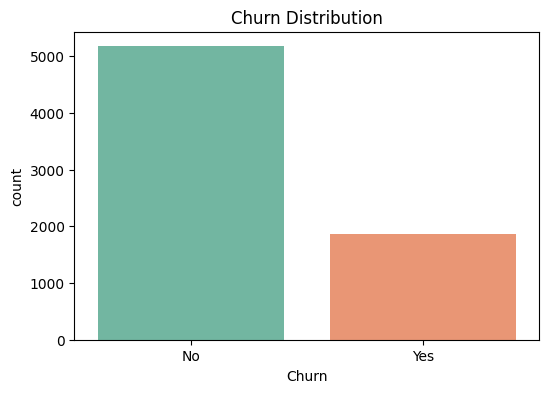

In [26]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)
plt.title('Churn Distribution')
plt.show()

**Churn By Contract Type**

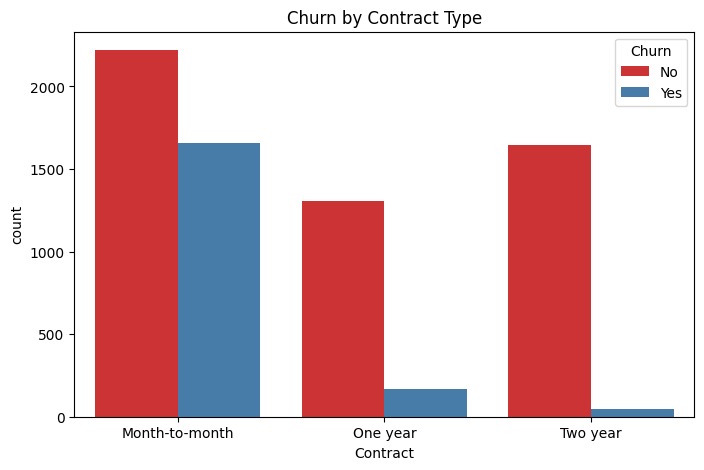

In [27]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set1')
plt.title('Churn by Contract Type')
plt.show()

**Monthly Charges vs Churn**

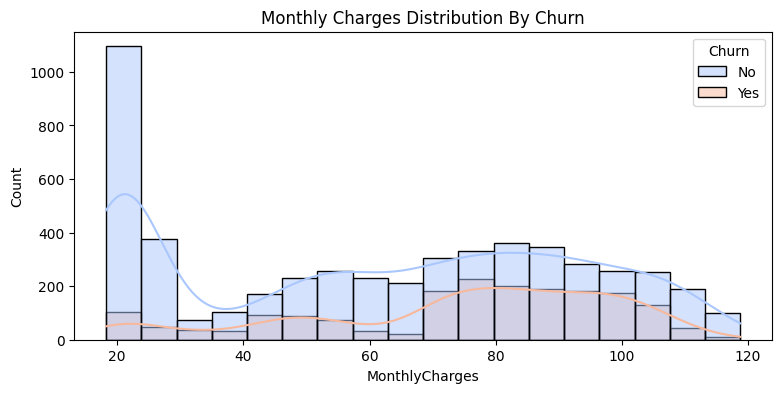

In [28]:
plt.figure(figsize=(9,4))
sns.histplot(data=df, x='MonthlyCharges', hue='Churn', kde=True, palette='coolwarm')
plt.title('Monthly Charges Distribution By Churn')
plt.show()

**Tenure vs Churn**

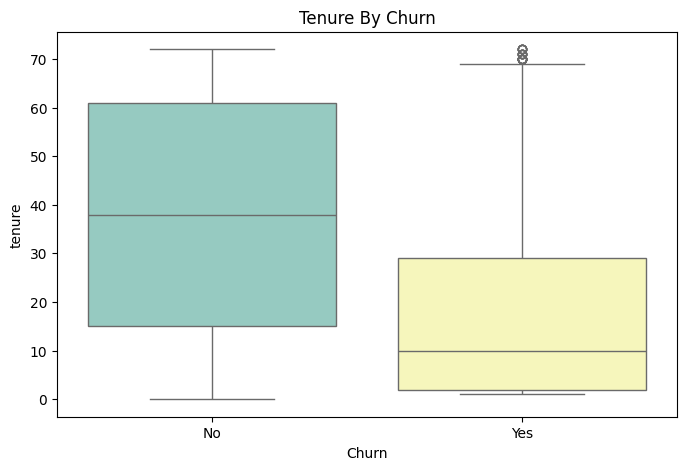

In [29]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Churn', y="tenure", hue='Churn', palette='Set3', legend=False)
plt.title('Tenure By Churn')
plt.show()

**Corelation & Features Importance**

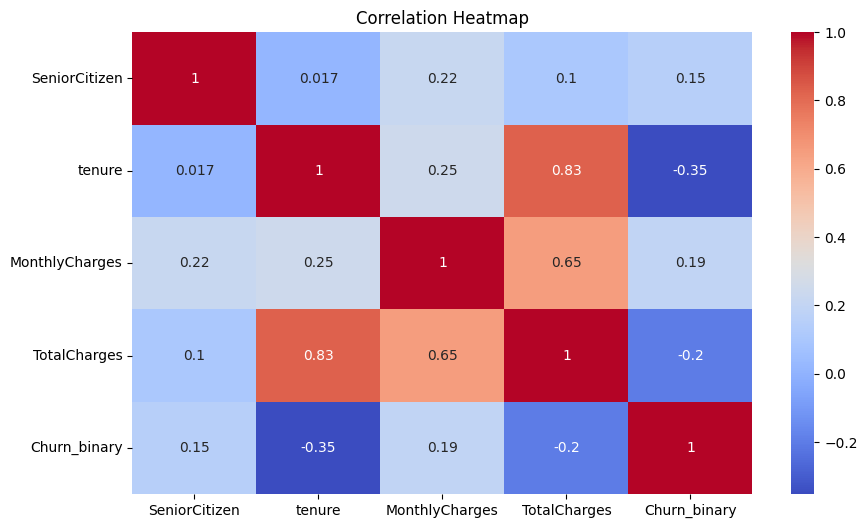

In [30]:
#Encode Churn Binary

df['Churn_binary'] = df['Churn'].map({'Yes':1, 'No':0})

#Numerical Corelation Heatmap

plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

**Insightful Observation**

In [32]:
# High Risk Churn Segment
high_churn = df[(df['Churn'] == 'Yes') & (df['Contract'] == 'Month-to-month')]

#Insight No.1 - What % of Churn comes from Month-to-month
percent_monthly = len(high_churn)/len(df[df['Churn'] == 'Yes'])*100
print(f"Insight: {percent_monthly:.2f} % of all churned customers were on Month-to-month contract")

#Insight No.2 - Senior Citizen more likely to churn
senior_churn_rate = df[df['SeniorCitizen']==1]['Churn_binary'].mean()
non_senior_churn_rate = df[df['SeniorCitizen'] == 0]['Churn_binary'].mean()
print(f"Insight: Senior Citizen Churn Rate = {senior_churn_rate: .2f}")
print(f"Insight: Non-Senior Citizen Churn Rate = {non_senior_churn_rate: .2f}")

Insight: 88.55 % of all churned customers were on Month-to-month contract
Insight: Senior Citizen Churn Rate =  0.42
Insight: Non-Senior Citizen Churn Rate =  0.24


In [40]:
df =df.drop('customerID', axis=1)

In [41]:
X = df.drop('Churn', axis = 1)
y = df['Churn']

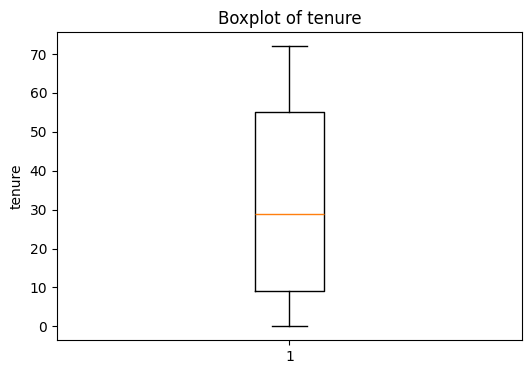

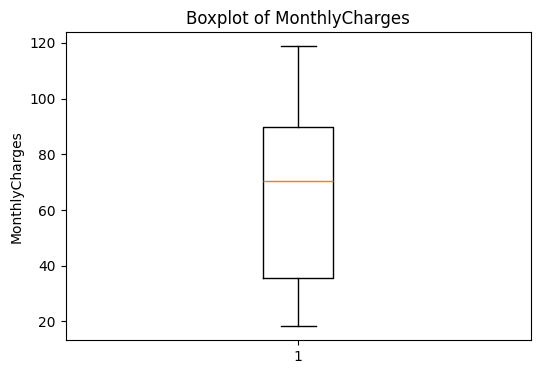

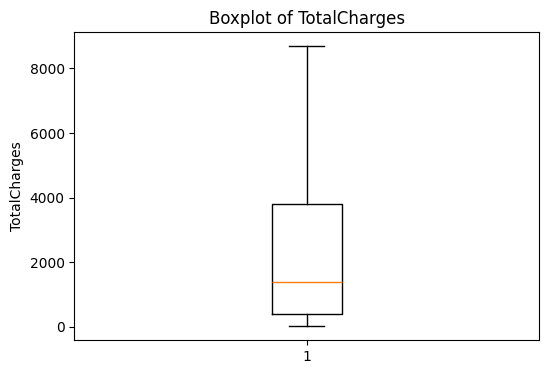

In [45]:
col = ['tenure', 'MonthlyCharges', 'TotalCharges']
for column in col:
  plt.figure(figsize=(6,4))
  plt.boxplot(X[column].dropna())
  plt.title(f'Boxplot of {column}')
  plt.ylabel(column)
  plt.show()

**Label Encoder**

In [47]:
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_binary
0,0,0,1,0,1,0,1,0,0,2,...,0,0,0,0,1,2,29.85,29.85,0,0
1,1,0,0,0,34,1,0,0,2,0,...,0,0,0,1,0,3,56.95,1889.50,0,0


In [48]:
cols = [col for col in df.columns if df[col].dtype == 'object']
cols

[]

In [49]:
for col in cols:
  le = LabelEncoder()
  df[col] = le.fit_transform(df[col])
df.head(2)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_binary
0,0,0,1,0,1,0,1,0,0,2,...,0,0,0,0,1,2,29.85,29.85,0,0
1,1,0,0,0,34,1,0,0,2,0,...,0,0,0,1,0,3,56.95,1889.50,0,0
